In [256]:
import os; os.chdir('/home/manh/server_code/from_scratch')
import torch
from torch import nn
import torch.nn.functional as F

In [257]:
import numpy as np
import matplotlib.pyplot as plt

In [258]:
x = np.linspace(0, 10, 100)
y = np.sin(x)

In [259]:
np.arange(0, 10)

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

In [367]:
class PlotHorizontalPrallelFunctions():
    def __init__(self, x, y_functions, x_ticks=None, W=15, h_per_plot=2):
        self.W = W
        self.h_per_plot = h_per_plot
        self.x = x
        self.x_ticks = x_ticks
        self.y_functions = y_functions
        self.num_plots = len(y_functions)
        plt.figure(figsize=(self.W, self.num_plots * self.h_per_plot))

    def add_plots(self):
        for i, y_func in enumerate(self.y_functions):
            plt.subplot(self.num_plots, 1, i + 1)
            plt.plot(self.x, y_func(self.x))

    def add_x_ticks(self, x_ticks=None):
        for i in range(self.num_plots):
            plt.subplot(self.num_plots, 1, i + 1)
            if x_ticks is not None:
                plt.xticks(x_ticks)
            
    def add_pos_marks(self, pos):
        for i, y_func in enumerate(self.y_functions):
            y_pos = y_func(np.array(pos))
            plt.subplot(self.num_plots, 1, i + 1)
            plt.scatter(pos, y_pos, c='red')
            for x, y in zip(pos, y_pos):
                plt.text(x, y, f"{y:.4f}")
        return self
    
    def plot(self):
        self.add_plots()
        return self
    
    def show(self):
        plt.show()

    def close(self):
        plt.close()

PlotHorizontalPrallelFunctions(
        x=np.linspace(0, 10, 100),
        y_functions=[np.sin, np.cos, np.tan],
        x_ticks=np.arange(0, 11),
        W=15, h_per_plot=2,)\
    .plot()\
    .add_pos_marks([2, 3, 4])\
    .close()

## Position on the y axis (row), and d_model on the x axis (column)

In [427]:
def pos_enc_row(seq_len=128, d_model=64, freq_constant=25):
    pos = torch.arange(1, seq_len + 1)
    pos_enc = torch.empty(seq_len, d_model)
    wave_freq_scaler = freq_constant ** (torch.arange(0, d_model, 2) / d_model)
    pos_enc[:, ::2] = torch.sin( pos.unsqueeze(1) / wave_freq_scaler[:(d_model - 1) // 2 + 1].unsqueeze(0) )
    pos_enc[:, 1::2] = torch.cos( pos.unsqueeze(1) / wave_freq_scaler[:d_model // 2].unsqueeze(0) )
    return pos_enc

## Position on the x axis (column), and d_model on the y axis (row)

In [428]:
def pos_enc_col(seq_len=128, d_model=64, freq_adj=25):
    freq_scaler = freq_adj ** (torch.arange(0, d_model, 2) / d_model)
    pos = torch.arange(1, seq_len + 1, dtype=torch.int64)
    pos_enc = torch.randn(d_model, seq_len)
    pos_enc[::2, :] = torch.sin( pos.unsqueeze(0) / freq_scaler[:(d_model - 1) // 2 + 1].unsqueeze(1) )
    pos_enc[1::2, :] = torch.cos( pos.unsqueeze(0) / freq_scaler[:d_model // 2].unsqueeze(1) )
    return pos_enc

In [432]:
(pos_enc_row() - pos_enc_col().T).abs().max()

tensor(0., device='cuda:0')

In [406]:
import seaborn as sns

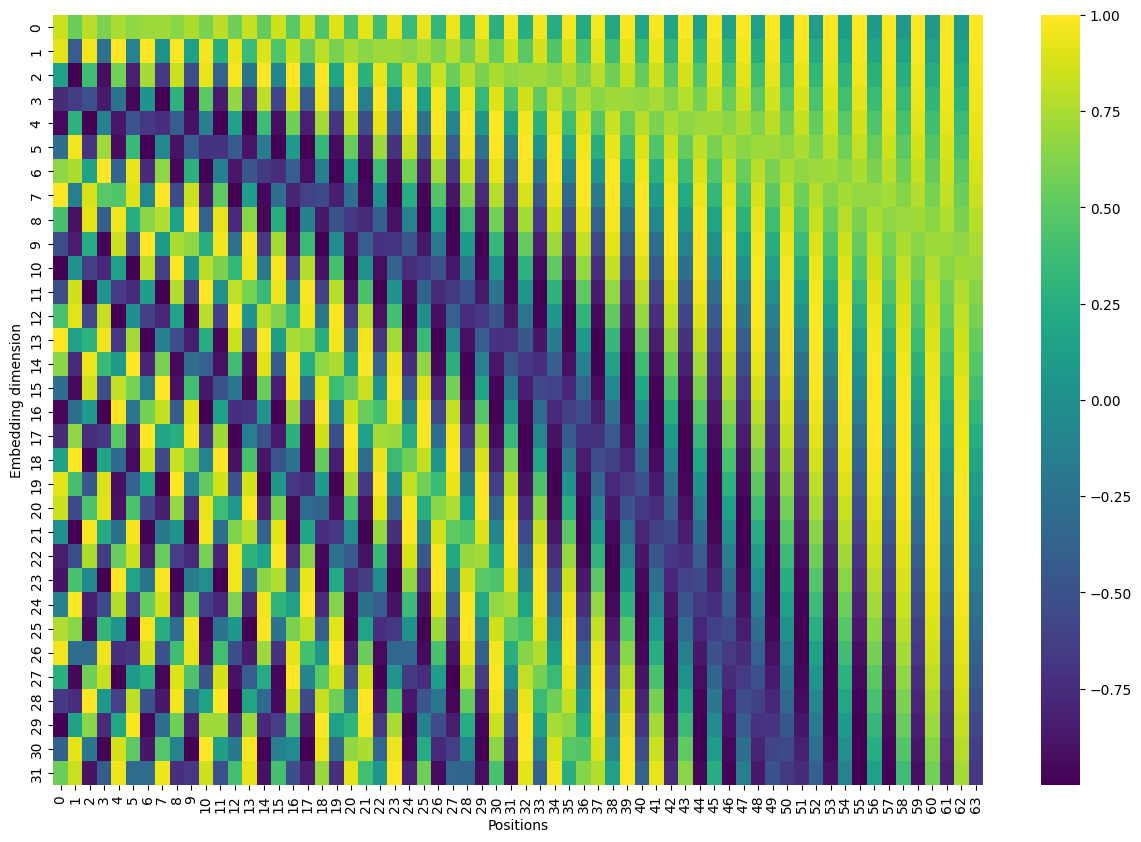

In [445]:
a = pos_enc_row(32, 64, 15).cpu().numpy()
plt.figure(figsize=(15, 10))
sns.heatmap(a, cmap='viridis', annot=False)
plt.xlabel('Positions')
plt.ylabel('Embedding dimension')
plt.show()

In [440]:
def pos_enc_col_manual_torch(seq_len=128, d_model=64, freq_adj=25):
    pos_enc = torch.empty(d_model, seq_len)
    for i in torch.arange(0, d_model):
        for pos in torch.arange(0, seq_len):
            if i % 2 == 0:
                pos_enc[i, pos] = torch.sin((pos + 1) / ( freq_adj ** ( i / d_model ) ))
            else:
                pos_enc[i, pos] = torch.cos((pos + 1) / ( freq_adj ** ( (i - 1) / d_model ) ))
    return pos_enc
(pos_enc_col_manual_torch() - pos_enc_col()).abs().max()

tensor(0., device='cuda:0')

In [ ]:
def pos_enc_col_manual_numpy(seq_len=128, d_model=64, freq_adj=25):
    pos_enc = np.zeros((d_model, seq_len))
    for i in np.arange(0, d_model):
        for pos in np.arange(0, seq_len):
            if i % 2 == 0:
                pos_enc[i, pos] = np.sin((pos + 1) / ( freq_adj ** ( i / d_model ) ))
            else:
                pos_enc[i, pos] = np.cos((pos + 1) / ( freq_adj ** ( (i - 1) / d_model ) ))

    return pos_enc
pos_enc_col_manual_numpy().round(4)

array([[ 0.8415,  0.9093,  0.1411, ...,  0.33  ,  0.9726,  0.721 ],
       [ 0.5403, -0.4161, -0.99  , ...,  0.944 ,  0.2324, -0.6929],
       [ 0.786 ,  0.9719,  0.4157, ...,  0.7479,  0.9841,  0.4689],
       ...,
       [ 0.9988,  0.9952,  0.9893, ...,  0.9928,  0.9975,  0.9998],
       [ 0.0442,  0.0884,  0.1323, ..., -0.6517, -0.6175, -0.5822],
       [ 0.999 ,  0.9961,  0.9912, ...,  0.7585,  0.7865,  0.8131]],
      shape=(64, 128))

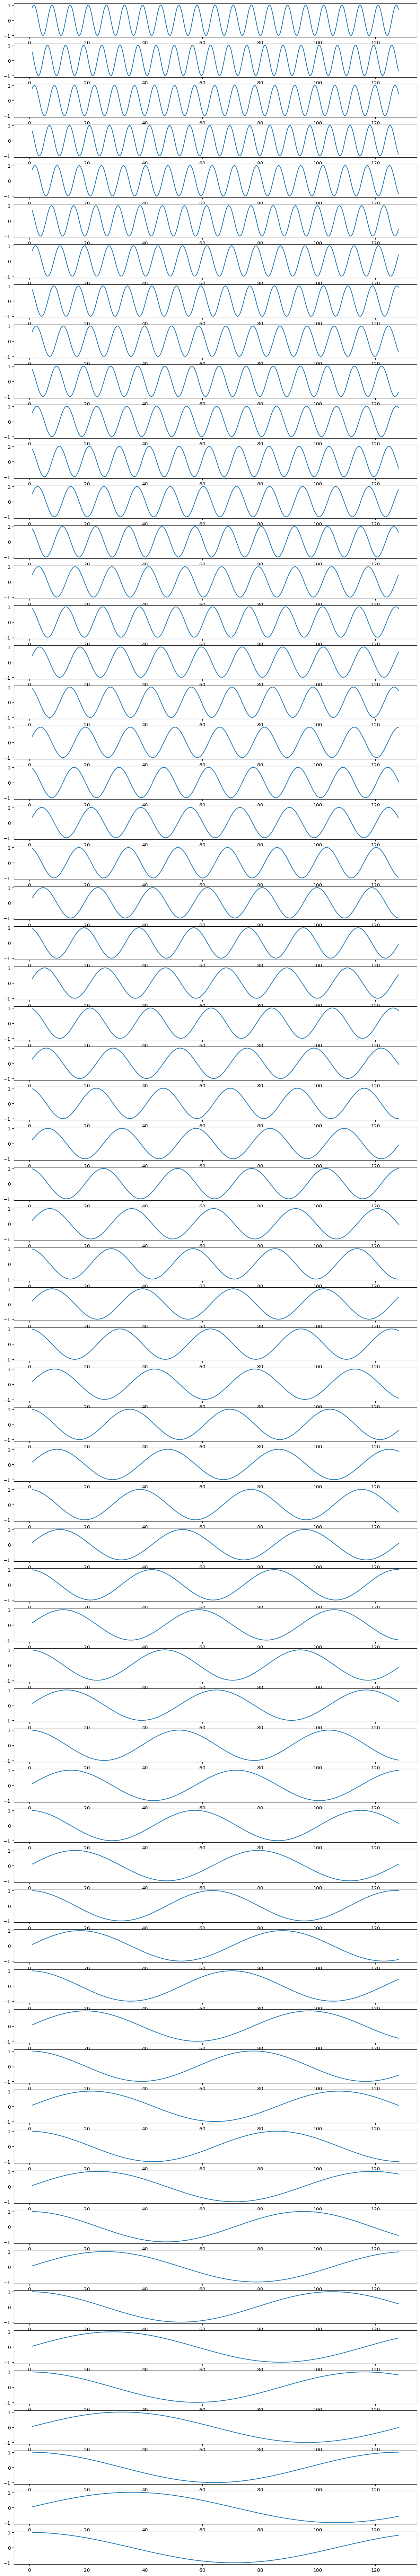

In [441]:
seq_len=128
d_model=64
freq_adj=25

y_functions = []
for i in range(0, d_model):
    if i % 2 == 0:
        y_functions.append(
            lambda pos, i=i: np.sin(pos / (freq_adj ** ( i / d_model )))
        )
    else:
        y_functions.append(
            lambda pos, i=i: np.cos(pos / (freq_adj ** ( (i - 1) / d_model )))
        )

PlotHorizontalPrallelFunctions(
        x=np.linspace(1, seq_len, 10000),
        y_functions=y_functions,
        W=15, h_per_plot=1.5)\
    .plot()\
    .add_pos_marks([])\
    .show()